In [ ]:
!nvidia-smi

Sat May  3 13:30:53 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# old dataset
# # Downloading Dataset
# !wget "https://s3-eu-west-1.amazonaws.com/pfigshare-u-files/21793293/Datos.rar"

# # Unzipping RAR File
# !unrar x Datos.rar

# # Clearing RAR FIle
# !rm -rf Datos.rar

--2025-05-03 12:23:22--  https://s3-eu-west-1.amazonaws.com/pfigshare-u-files/21793293/Datos.rar
Resolving s3-eu-west-1.amazonaws.com (s3-eu-west-1.amazonaws.com)... 52.92.33.184, 52.218.57.107, 52.218.44.184, ...
Connecting to s3-eu-west-1.amazonaws.com (s3-eu-west-1.amazonaws.com)|52.92.33.184|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10985259 (10M) [application/rar]
Saving to: ‘Datos.rar’

Datos.rar           100%[===================>]  10.48M  9.86MB/s    in 1.1s    

2025-05-03 12:23:23 (9.86 MB/s) - ‘Datos.rar’ saved [10985259/10985259]


UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from Datos.rar

Creating    Datos                                                     OK
Creating    Datos/Testing                                             OK
Creating    Datos/Testing/Chronic otitis media                        OK
Extracting  Datos/Testing/Chronic otitis media/o1.jpg                      0%  OK 
Extr

In [ ]:
import kagglehub
import shutil
import os

# Define the Colab directory where you want to save the dataset
save_dir = "/content"
os.makedirs(save_dir, exist_ok=True)

# Download the dataset using kagglehub
dataset_path = kagglehub.dataset_download("ucimachinelearning/otoscopic-image-dataset")

shutil.copytree(dataset_path, save_dir, dirs_exist_ok=True)

print("Dataset saved to:", save_dir)

100%|██████████| 86.6M/86.6M [00:02<00:00, 31.8MB/s]

Extracting files...


Dataset saved to: /content


In [ ]:
import os
import glob
import shutil
import random # Needed for shuffling files
from tqdm import tqdm

# --- Configuration ---

# Base source directory path
SOURCE_BASE_DIR = "/content/Otoscopic_Data"

# Train/Test split ratio
TRAIN_SPLIT_RATIO = 0.8 # 80% for training, 20% for testing

# image categories mapping (Target folder name -> Source folder name)
# Using the exact source names provided, mapping to clean target names
categories = {
    "acute-otitis-media": "Acute Otitis Media",
    "cerumen-impaction": "Cerumen Impaction",
    "chronic-otitis-media": "Chronic Otitis Media",
    "myringosclerosis": "Myringosclerosis",
    "normal": "Normal"
}

# --- Script Logic ---

# Clearing existing dataset folder to start fresh
print("Clearing existing 'datasets/' folder...")
if os.path.exists("datasets"):
    shutil.rmtree("datasets/")
print("'datasets/' folder cleared (if it existed).")

# Preparing the new dataset folders structure (train and test for each category)
print("Preparing new 'datasets/' folder structure...")
target_category_folders = categories.keys() # Get the list of desired folder names

for dataset_type in ["train", "test"]:
    for category_folder_name in target_category_folders:
        # Construct the full path like 'datasets/train/acute-otitis-media'
        path_to_create = os.path.join("datasets", dataset_type, category_folder_name)
        os.makedirs(path_to_create, exist_ok=True)
        # print(f"Created: {path_to_create}") # Uncomment for detailed creation logs
print("'datasets/' folder structure created.")


# Copying and splitting files from source to new dataset folders
print(f"Starting file copying and splitting from '{SOURCE_BASE_DIR}/'...")

# Loop through each category to process its files
for target_cat_folder_name, source_cat_folder_name in tqdm(categories.items(), desc="Processing Categories"):

    # Construct the source path for the current category (e.g., '/content/Otoscopic_Data/Acute Otitis Media/*')
    source_category_path = os.path.join(SOURCE_BASE_DIR, source_cat_folder_name)
    source_path_pattern = os.path.join(source_category_path, "*")

    # Get the list of all files in the source category folder
    all_files = glob.glob(source_path_pattern)

    if not all_files:
        print(f"Warning: No files found in source directory: {source_category_path}")
        continue # Skip this category if no files are found

    # Shuffle the list of files randomly
    random.shuffle(all_files)

    # Calculate the split index
    split_index = int(len(all_files) * TRAIN_SPLIT_RATIO)

    # Split the files into training and testing lists
    train_files = all_files[:split_index]
    test_files = all_files[split_index:]

    print(f"\n  Category '{source_cat_folder_name}': {len(all_files)} files found.")
    print(f"    Splitting: {len(train_files)} for training, {len(test_files)} for testing.")

    # Copy training files
    destination_base_path_train = os.path.join("datasets", "train", target_cat_folder_name)
    for data_filepath in tqdm(train_files, desc=f"    Copying Train files to {os.path.join('train', target_cat_folder_name)}", leave=False):
        filename = os.path.basename(data_filepath)
        destination_filepath = os.path.join(destination_base_path_train, filename)
        shutil.copyfile(data_filepath, destination_filepath)

    # Copy testing files
    destination_base_path_test = os.path.join("datasets", "test", target_cat_folder_name)
    for data_filepath in tqdm(test_files, desc=f"    Copying Test files to {os.path.join('test', target_cat_folder_name)}", leave=False):
        filename = os.path.basename(data_filepath)
        destination_filepath = os.path.join(destination_base_path_test, filename)
        shutil.copyfile(data_filepath, destination_filepath)

print("\nFile copying and splitting complete.")

# Clearing old source data folder - Removing the top-level Otoscopic_Data folder
print(f"Clearing old source folder '{SOURCE_BASE_DIR}/'...")
if os.path.exists(SOURCE_BASE_DIR):
    shutil.rmtree(SOURCE_BASE_DIR)
    print(f"'{SOURCE_BASE_DIR}/' folder cleared.")
else:
    print(f"'{SOURCE_BASE_DIR}/' folder not found, no need to clear.")

print("Script finished.")

Clearing existing 'datasets/' folder...
'datasets/' folder cleared (if it existed).
Preparing new 'datasets/' folder structure...
'datasets/' folder structure created.
Starting file copying and splitting from '/content/Otoscopic_Data/'...


Processing Categories:   0%|          | 0/5 [00:00<?, ?it/s]


  Category 'Acute Otitis Media': 600 files found.
    Splitting: 480 for training, 120 for testing.



    Copying Train files to train/acute-otitis-media:   0%|          | 0/480 [00:00<?, ?it/s]
                                                                                            
    Copying Test files to test/acute-otitis-media:   0%|          | 0/120 [00:00<?, ?it/s]
                                                                                          


  Category 'Cerumen Impaction': 600 files found.
    Splitting: 480 for training, 120 for testing.


...


  Category 'Myringosclerosis': 600 files found.
    Splitting: 480 for training, 120 for testing.



    Copying Train files to train/myringosclerosis:   0%|          | 0/480 [00:00<?, ?it/s]
                                                                                          
Processing Categories:  80%|████████  | 4/5 [00:00<00:00, 13.56it/s]


  Category 'Normal': 600 files found.
    Splitting: 480 for training, 120 for testing.



    Copying Train files to train/normal:   0%|          | 0/480 [00:00<?, ?it/s]
                                                                                
Processing Categories: 100%|██████████| 5/5 [00:00<00:00, 13.78it/s]



File copying and splitting complete.
Clearing old source folder '/content/Otoscopic_Data/'...
'/content/Otoscopic_Data/' folder cleared.
Script finished.


In [ ]:
# --- Setup and Imports ---
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.models import resnet50, ResNet50_Weights
from torch.backends import cudnn

In [ ]:
# --- Environment Setup ---
cudnn.benchmark = True
plt.ion()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize(256), # Resize the smaller edge of the image to 256 pixels while maintaining aspect ratio.
        transforms.CenterCrop(224), # Crop the central 224x224 patch from the resized image. ResNet-50 expects 224x224 input.
        transforms.ColorJitter(), # Randomly changes the brightness, contrast, saturation, and hue of the image. (Augmentation)
        transforms.RandomHorizontalFlip(), # Randomly flips the image horizontally with a default probability of 0.5. (Augmentation)
        transforms.ToTensor(), # Converts the image from a PIL Image or NumPy array to a PyTorch Tensor (HWC to CHW) and scales pixel values from [0, 255] to [0.0, 1.0].
        transforms.Normalize([0.485, 0.456, 0.406], # Normalize the tensor with the mean of the ImageNet dataset. These are common values.
                             [0.229, 0.224, 0.225]) # Normalize with the standard deviation of the ImageNet dataset.
    ]),
    'test': transforms.Compose([
        transforms.Resize(256), # Same as train: Resize smaller edge to 256.
        transforms.CenterCrop(224), # Same as train: Crop the central 224x224. For testing, you want a consistent crop representative of the center.
        transforms.ToTensor(), # Same as train: Convert to Tensor and scale to [0, 1].
        transforms.Normalize([0.485, 0.456, 0.406], # Same as train: Normalize using ImageNet mean and std dev.
                             [0.229, 0.224, 0.225])
    ]),
}

In [ ]:
# --- Data Loading ---

# Define the directory where your prepared dataset is located
data_dir = 'datasets'

# Create training and testing datasets using ImageFolder
# ImageFolder automatically reads images and assigns labels based on folder names
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'test']}

# Create DataLoaders for training and testing sets
# DataLoaders handle batching and shuffling the data
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, # You can adjust batch_size
                                             shuffle=True if x == 'train' else False, # Shuffle training data
                                             num_workers=4) # Number of subprocesses for data loading (adjust based on CPU cores)
               for x in ['train', 'test']}

# Get the size of the datasets
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}

# Get the class names (folder names are used as class names by ImageFolder)
class_names = image_datasets['train'].classes

print(f"Dataset loaded from: {data_dir}")
print(f"Classes: {class_names}")
print(f"Dataset sizes: Train={dataset_sizes['train']}, Test={dataset_sizes['test']}")

Dataset loaded from: datasets
Classes: ['acute-otitis-media', 'cerumen-impaction', 'chronic-otitis-media', 'myringosclerosis', 'normal']
Dataset sizes: Train=2400, Test=600


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


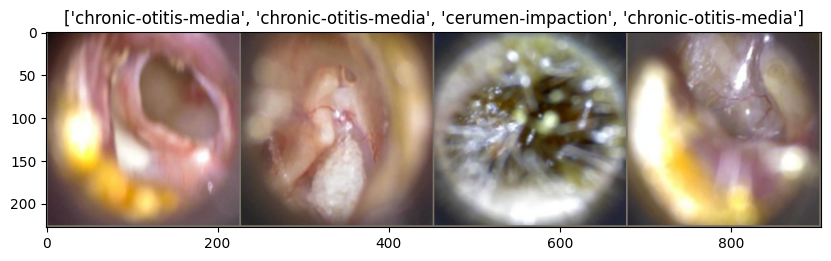

In [ ]:
# --- Image Visualization ---

# Helper function to display a tensor as an image
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0)) # Convert from Tensor (CHW) to NumPy (HWC)
    # Un-normalize the image using the mean and std deviation used in transforms.Normalize
    # Mean and Std Dev tensors match the shape expected for broadcasting (3 channels)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean # Reverse the normalization: inp * std + mean
    inp = np.clip(inp, 0, 1) # Clip values to be between 0 and 1 just in case

    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # Pause a bit so that plots are updated

# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs) # Arrange images in a grid

# Display the grid and set titles based on classes
plt.figure(figsize=(10, 10)) # Adjust figure size as needed
imshow(out, title=[class_names[x] for x in classes])
plt.show() # Keep the plot window open

# Note: If you want to display more images, you can grab more batches
# or modify the code to iterate through more items in the first batch.

In [ ]:
# --- Get Number of Classes ---
# Assumes 'class_names' variable is available from the data loading section
num_classes = len(class_names)
print(f"\nNumber of classes in the dataset: {num_classes}")


Number of classes in the dataset: 5


In [ ]:
# --- Model Definition ---
class CustomResNet50(nn.Module):
    def __init__(self, num_classes):
        """
        Initializes the CustomResNet50 model for transfer learning.

        Args:
            num_classes (int): The number of output classes for the classifier.
        """
        super(CustomResNet50, self).__init__()

        # Load the pre-trained ResNet-50 model with ImageNet weights
        # weights=ResNet50_Weights.IMAGENET1K_V2 gets the latest recommended weights
        self.model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

        # --- Freezing the base model parameters ---
        # We freeze the parameters of the pre-trained model so they are not updated during training.
        # This preserves the powerful features learned on the large ImageNet dataset.
        for param in self.model.parameters():
            param.requires_grad = False
        # --- End Freezing ---

        # Get the number of input features for the final fully connected layer
        # ResNet's final layer is 'fc' (fully connected)
        in_features = self.model.fc.in_features

        # --- Modify the final classification layer ---
        # Replace the original ImageNet classifier (which outputs 1000 classes)
        # with a new sequential layer that outputs 'num_classes'.
        # Added intermediate layers and dropout for potentially better performance
        # on the new task and to help prevent overfitting.
        self.model.fc = nn.Sequential(
            nn.Linear(in_features, in_features // 2), # First linear layer
            nn.ReLU(), # Activation function
            nn.Dropout(0.5), # Dropout for regularization
            nn.Linear(in_features // 2, in_features // 4), # Second linear layer
            nn.ReLU(), # Activation function
            nn.Dropout(0.5), # Dropout for regularization
            nn.Linear(in_features // 4, in_features // 8), # Third linear layer
            nn.ReLU(), # Activation function
            nn.Dropout(0.25), # Reduced dropout for the layer closest to the output
            nn.Linear(in_features // 8, num_classes), # Final linear layer outputting num_classes
        )
        # --- End Modification ---

    def forward(self, x):
        """
        Defines the forward pass of the model.

        Args:
            x (torch.Tensor): Input tensor (image batch).

        Returns:
            torch.Tensor: Output tensor (logits).
        """
        # Simply pass the input through the ResNet model structure
        return self.model(x)

# Example of how to instantiate the model (you'll need num_classes, which is len(class_names))
# num_classes = len(class_names) # Assuming class_names is available from data loading
# model = CustomResNet50(num_classes=num_classes)
# model = model.to(device) # Move the model to the selected device (GPU or CPU)

In [ ]:
model = CustomResNet50(num_classes=num_classes).to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]


In [ ]:
# --- Training Setup ---
learning_rate = 0.001
num_epochs = 50
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
# --- Training Loop ---
# Assumes 'model', 'loss_fn', 'optimizer', 'dataloaders' (as train_loader/test_loader),
# 'num_epochs', 'device', and 'num_classes' are defined.
# Note: If you switch loss_fn to nn.CrossEntropyLoss(), the loss calculation lines will change.

def train(model, loss_fn, optimizer, dataloaders, num_epochs, device, num_classes):
    """
    Trains and evaluates the model over multiple epochs.

    Args:
        model (nn.Module): The model to train.
        loss_fn: The loss function.
        optimizer: The optimizer.
        dataloaders (dict): Dictionary containing 'train' and 'test' DataLoaders.
        num_epochs (int): Number of training epochs.
        device (torch.device): The device (cuda or cpu) to use.
        num_classes (int): The total number of classes.
    """
    print("\nStarting training loop...")
    start_time = time.time()

    # Store history for plotting later (optional)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print('-' * 10)

        # --- Training Phase ---
        model.train()  # Set model to training mode
        running_loss = 0.0
        running_corrects = 0
        total_samples = 0

        # Iterate over data in batches
        # Added tqdm for progress bar during epoch
        for images, labels in tqdm(dataloaders['train'], desc=f"  Training Epoch {epoch+1}"):
            # Move data to the appropriate device
            images = images.to(device)
            labels = labels.to(device) # Labels are class indices (LongTensor)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images) # Model outputs raw logits (scores)

            # --- Calculate Loss ---
            # Assuming loss_fn is nn.BCEWithLogitsLoss() and needs one-hot targets
            # CORRECTED F.one_hot call with num_classes
            targets_one_hot = F.one_hot(labels, num_classes=num_classes).float()
            loss = loss_fn(outputs, targets_one_hot)

            # --- Alternative if using nn.CrossEntropyLoss() (RECOMMENDED for multi-class) ---
            # If loss_fn = nn.CrossEntropyLoss(), the calculation is simpler:
            # loss = loss_fn(outputs, labels) # CrossEntropyLoss expects raw logits and class indices
            # --- End Alternative ---

            # Get model predictions (for calculating accuracy)
            # torch.max returns (values, indices). We only need the indices (predicted class)
            _, preds = torch.max(outputs, 1) # Get the index of the max log-probability

            # Backward pass and optimize
            loss.backward() # Compute gradient of the loss w.r.t. parameters
            optimizer.step() # Update model parameters

            # Accumulate statistics
            # loss.item() gets the scalar value of the loss for the current batch
            # images.size(0) is the batch size
            running_loss += loss.item() * images.size(0)
            # torch.sum checks where predictions match true labels
            running_corrects += torch.sum(preds == labels.data) # Use labels.data for clarity/compatibility

            total_samples += images.size(0)


        # Calculate average loss and accuracy for the epoch
        train_loss = running_loss / total_samples
        train_acc = running_corrects.double() / total_samples # Use double for accuracy calculation


        # --- Evaluation Phase ---
        model.eval() # Set model to evaluate mode
        running_test_loss = 0.0
        running_test_corrects = 0
        total_test_samples = 0

        # Disable gradient calculation for evaluation
        with torch.no_grad():
            # Iterate over data in the test loader - Loop over ALL batches
            for test_images, test_labels in tqdm(dataloaders['test'], desc=f"  Testing Epoch {epoch+1} "):
                 # Move data to the appropriate device
                test_images = test_images.to(device)
                test_labels = test_labels.to(device) # Labels are class indices (LongTensor)

                # Forward pass
                test_outputs = model(test_images)

                # --- Calculate Loss for Test Set ---
                # Assuming loss_fn is nn.BCEWithLogitsLoss() and needs one-hot targets
                # CORRECTED F.one_hot call with num_classes
                test_targets_one_hot = F.one_hot(test_labels, num_classes=num_classes).float()
                test_loss_batch = loss_fn(test_outputs, test_targets_one_hot)

                # --- Alternative if using nn.CrossEntropyLoss() (RECOMMENDED for multi-class) ---
                # If loss_fn = nn.CrossEntropyLoss(), the calculation is simpler:
                # test_loss_batch = loss_fn(test_outputs, test_labels) # CrossEntropyLoss expects raw logits and class indices
                # --- End Alternative ---


                # Get model predictions (for calculating accuracy)
                _, test_preds = torch.max(test_outputs, 1) # Get the index of the max log-probability

                # Accumulate statistics for the test set
                running_test_loss += test_loss_batch.item() * test_images.size(0)
                running_test_corrects += torch.sum(test_preds == test_labels.data)
                total_test_samples += test_images.size(0)

        # Calculate average loss and accuracy for the test set
        test_loss = running_test_loss / total_test_samples
        test_acc = running_test_corrects.double() / total_test_samples # Use double for accuracy


        # Print epoch results
        print(f"  [Epoch {epoch+1:02d}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} || "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}")

        # Store metrics (optional)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc.item()) # Convert tensor to scalar for list
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc.item())   # Convert tensor to scalar for list


    time_elapsed = time.time() - start_time
    print(f"\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Test Acc: {max(history['test_acc']):.4f}")

    # You can return the trained model and history if needed
    # return model, history

# --- How to call the train function ---
# Assuming model, loss_fn, optimizer, dataloaders, num_epochs, device, num_classes are defined
# train(model, loss_fn, optimizer, dataloaders, num_epochs, device, num_classes)

In [ ]:
# --- Run Training ---
train(model, loss_fn, optimizer, dataloaders, num_epochs, device, num_classes)


Starting training loop...

Epoch 1/50
----------


  Testing Epoch 1 : 100%|██████████| 150/150 [00:05<00:00, 26.68it/s]


  [Epoch 01] Train Loss: 0.3504, Train Acc: 0.5271 || Test Loss: 0.1874, Test Acc: 0.7817

Epoch 2/50
----------


  Testing Epoch 2 : 100%|██████████| 150/150 [00:03<00:00, 42.28it/s]


  [Epoch 02] Train Loss: 0.2393, Train Acc: 0.7033 || Test Loss: 0.1137, Test Acc: 0.9217

Epoch 3/50
----------


...

  [Epoch 48] Train Loss: 0.0756, Train Acc: 0.9383 || Test Loss: 0.0234, Test Acc: 0.9800

Epoch 49/50
----------


  Testing Epoch 49 : 100%|██████████| 150/150 [00:04<00:00, 32.32it/s]


  [Epoch 49] Train Loss: 0.0568, Train Acc: 0.9433 || Test Loss: 0.0263, Test Acc: 0.9800

Epoch 50/50
----------


  Testing Epoch 50 : 100%|██████████| 150/150 [00:03<00:00, 40.35it/s]

  [Epoch 50] Train Loss: 0.0673, Train Acc: 0.9417 || Test Loss: 0.0203, Test Acc: 0.9867

Training complete in 17m 42s
Best Test Acc: 0.9867


In [ ]:
# --- Save the Model ---
#torch.save(model.state_dict(), "ome.pt")

In [ ]:
!pip install onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 9.1 MB/s eta 0:00:00


In [ ]:
# --- Export Model to ONNX Format ---

# Ensure you have imported the onnx module from torch
import torch.onnx

# Assuming 'model' (your trained CustomResNet50 model instance),
# and 'device' (the device your model is currently on) are defined from previous steps.
# Also assumes your model expects input images of shape (Batch Size, 3, 224, 224)
# after transformations, which is standard for ResNet-50.

# Define the name for the output ONNX file
onnx_filename = "ome.onnx"

# --- Create a dummy input tensor ---
# This tensor is needed by the ONNX exporter to trace the path of data
# through the model's operations.
# The shape should match the expected input shape of your model (Batch Size, Channels, Height, Width).
# A batch size of 1 is standard for tracing, and (3, 224, 224) matches your image transformations.
dummy_input = torch.randn(1, 3, 224, 224).to(device)

print(f"\nPreparing to export model to ONNX format: {onnx_filename}")

try:
    # Use torch.onnx.export() to perform the conversion
    torch.onnx.export(model,             # The PyTorch model instance to export
                      dummy_input,       # The dummy input tensor for tracing
                      onnx_filename,     # The file path to save the ONNX model to
                      export_params=True,# Set to True to include the model's trained parameters in the ONNX file
                      opset_version=13,  # Specify the ONNX opset version. Choose a version compatible with your target runtime.
                                         # Opset 13 or a more recent stable one like 14 or 15 is often a good choice.
                      do_constant_folding=True, # Apply optimization like constant folding during the export

                      # --- Optional: Define Input/Output names and Dynamic axes ---
                      # Naming inputs/outputs is helpful for using the ONNX model in other runtimes.
                      # Dynamic axes allow dimensions (like batch size) to be flexible.
                      input_names = ['input'],     # Name for the input node in the ONNX graph
                      output_names = ['output'],   # Name for the output node in the ONNX graph
                      dynamic_axes={'input' : {0 : 'batch_size'},  # Make the 0th dimension (batch size) of the input dynamic
                                    'output' : {0 : 'batch_size'}}) # Make the 0th dimension (batch size) of the output dynamic
                      # --- End Optional Arguments ---

    print(f"Model successfully exported to {onnx_filename}")

    # --- Optional: Verify the exported ONNX model ---
    # You can use the 'onnx' library to check if the exported model is valid.
    # This requires the 'onnx' package to be installed (`pip install onnx`).
    try:
        import onnx
        onnx_model = onnx.load(onnx_filename)
        onnx.checker.check_model(onnx_model) # Checks the model's structure and validity
        print("ONNX model verification successful!")
    except ImportError:
        print("ONNX library not installed. Skipping model verification.")
    except Exception as e:
        print(f"ONNX model verification failed: {e}")


except Exception as e:
    print(f"An error occurred during ONNX export: {e}")


Preparing to export model to ONNX format: ome.onnx
Model successfully exported to ome.onnx
ONNX model verification successful!


# Prediction for the image

In [ ]:
# If these imports were not in your initial imports cell, include them here
from PIL import Image
import torchvision.transforms as transforms
import torch
import numpy as np
import matplotlib.pyplot as plt # Needed for displaying the image
import glob # Useful for finding example images in your prepared dataset
import os # Useful for path joining and checking file existence

In [ ]:
# --- Define the Prediction Function ---
def predict_single_image(model, image_path, test_transforms, class_names, device):
    """
    Loads a single image, preprocesses it, and predicts its class using the trained model.

    Args:
        model (nn.Module): The trained PyTorch model.
        image_path (str): Path to the input image file.
        test_transforms: The torchvision transforms for test data (data_transforms['test']).
        class_names (list): List of class names (e.g., ['acute-otitis-media', ...]).
        device (torch.device): The device (cuda or cpu) the model is on.

    Returns:
        str: The predicted class name. Returns None if image loading fails.
        torch.Tensor: The probability scores for all classes (as a 1D tensor). Returns None if image loading fails.
    """
    model.eval() # Set model to evaluation mode
    try:
        image = Image.open(image_path).convert('RGB') # Load and convert to RGB
        print(f"\nLoading image for prediction: {image_path}")
    except FileNotFoundError:
        print(f"Error: Image file not found at {image_path}")
        return None, None
    except Exception as e:
        print(f"Error loading image {image_path}: {e}")
        return None, None

    image = test_transforms(image) # Apply test transformations
    image = image.unsqueeze(0) # Add batch dimension
    image = image.to(device) # Move image to the same device as the model

    with torch.no_grad(): # Disable gradient calculation for inference
        outputs = model(image) # Forward pass

    probabilities = torch.softmax(outputs, dim=1) # Convert logits to probabilities
    _, predicted_class_index = torch.max(probabilities, 1) # Get predicted class index
    predicted_class_index = predicted_class_index.item() # Get scalar index

    predicted_class_name = class_names[predicted_class_index] # Get class name

    return predicted_class_name, probabilities.squeeze(0) # Return name and scores


Loading image for prediction: /content/datasets/test/chronic-otitis-media/com (161).jpg

--- Prediction Results ---
Image File: com (161).jpg
Predicted Class: chronic-otitis-media

Class Probabilities:
  chronic-otitis-media: 1.0000
  normal: 0.0000
  myringosclerosis: 0.0000
  cerumen-impaction: 0.0000
  acute-otitis-media: 0.0000


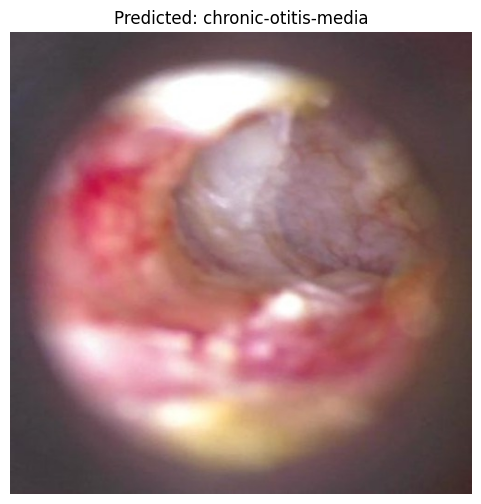

In [ ]:
# --- Example Usage: Testing with a Specific Image Path ---

# This code block assumes that you have already executed the cells that define:
# - Imports (like PIL, torch, torchvision.transforms, numpy, matplotlib.pyplot, os)
# - 'model' (your trained or loaded model instance)
# - 'data_transforms' (specifically data_transforms['test'])
# - 'class_names' (the list of your dataset's category names)
# - 'device' (e.g., torch.device('cuda:0'))
# - The 'predict_single_image' function definition itself.

# --- Specify the path to the image you want to test ---
# Set the path directly to the specific image file in your Colab environment.
# Make sure this path is correct and the file exists.
image_to_test_path = '/content/datasets/test/chronic-otitis-media/com (161).jpg'

# --- Example using Method 3 (image from prepared test set) - COMMENTED OUT ---
# This block is commented out to ensure the manually set 'image_to_test_path' above is used.
# If you want to test a random image from a category, you can uncomment this block
# and comment out the 'image_to_test_path = ...' line above.
# try:
#     import glob # Ensure glob is imported if using this block
#     import os   # Ensure os is imported if using this block
#     # Specify the category folder you want to sample from (e.g., 'Normal')
#     test_category_to_sample = 'Normal'
#     test_category_folder_path = os.path.join('datasets', 'test', test_category_to_sample)
#     list_of_test_images = glob.glob(os.path.join(test_category_folder_path, '*'))

#     if list_of_test_images:
#         # Pick the first image found as the example
#         image_to_test_path = list_of_test_images[0]
#         print(f"\n--- Using example image from test set: {image_to_test_path} ---")
#     else:
#         print(f"\n--- No images found in {test_category_folder_path}. Please provide a direct path to an image or check the folder. ---")
#         image_to_test_path = None # Set path to None if no images found

# except Exception as e:
#     print(f"\n--- Error while trying to find example image from test set: {e} ---")
#     image_to_test_path = None


# --- Run the prediction if a valid image path is available ---
# Check if the image path was successfully set and the file exists at that path
if image_to_test_path and os.path.exists(image_to_test_path):
    # Call the predict_single_image function with the specified path
    predicted_class, scores = predict_single_image(model, image_to_test_path, data_transforms['test'], class_names, device)

    # --- Display the prediction results ---
    if predicted_class: # Check if the prediction function successfully loaded and processed the image
        print(f"\n--- Prediction Results ---")
        print(f"Image File: {os.path.basename(image_to_test_path)}") # Print just the filename for clarity
        print(f"Predicted Class: {predicted_class}")

        # Optional: Print the probability scores for all classes
        print("\nClass Probabilities:")
        # Create a list of (class_name, probability) tuples
        prob_list = [(class_names[i], scores[i].item()) for i in range(len(class_names))]
        # Sort the list by probability in descending order for easier interpretation
        prob_list.sort(key=lambda item: item[1], reverse=True)

        # Print the sorted probabilities
        for class_name, prob in prob_list:
            print(f"  {class_name}: {prob:.4f}")

        # Optional: Display the image itself with the prediction title using Matplotlib
        # This loads the image again using PIL just for visualization (no transforms)
        try:
            # Ensure matplotlib.pyplot is imported as plt
            display_img = Image.open(image_to_test_path)
            plt.figure(figsize=(6, 6)) # Set the size of the figure
            plt.imshow(display_img)    # Display the image
            plt.title(f"Predicted: {predicted_class}") # Set title to the prediction
            plt.axis('off') # Turn off axis labels and ticks for a clean image display
            plt.show() # Display the plot window in Colab
        except Exception as e:
            print(f"Could not display image using Matplotlib: {e}")

    else:
        # This message will print if the predict_single_image function returned None due to an error (like file not found initially)
        print("\nPrediction could not be made due to an error during processing.")

else:
    # This message will print if the image_to_test_path variable was not set or the file does not exist at the path
    print("\nPrediction skipped because the specified image path was not valid or the file does not exist at that location.")

--- Upload an image file from your computer for prediction ---
Click 'Choose Files' below to select the image.


Saving o.webp to o.webp

Successfully uploaded 'o.webp' and saved to '/content/o.webp' in Colab.

Loading image for prediction: /content/o.webp

--- Prediction Results ---
Image File: o.webp
Predicted Class: chronic-otitis-media

Class Probabilities:
  chronic-otitis-media: 0.9758
  normal: 0.0131
  myringosclerosis: 0.0089
  cerumen-impaction: 0.0020
  acute-otitis-media: 0.0002


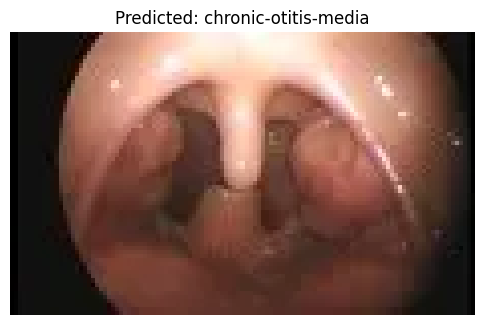

In [ ]:
# --- Code Block for Uploading Image and Predicting (Corrected Import) ---

# --- Ensure Necessary Imports ---
# The 'files' object comes from google.colab.files. THIS LINE IS REQUIRED.
from google.colab import files

# You will also need these imports if they weren't in your very first imports cell:
import io # For handling file content as bytes
import os # For path joining and file operations
import torch # For tensors and moving data
import torchvision.transforms as transforms # For applying test transforms
from PIL import Image # For opening the image file
import numpy as np # Often needed when working with image data
import matplotlib.pyplot as plt # Needed for displaying the image


# --- Prerequisites ---
# Ensure you have already executed cells that define:
# - 'model' (your trained or loaded model instance)
# - 'data_transforms' (specifically data_transforms['test'])
# - 'class_names' (the list of your dataset's category names)
# - 'device' (e.g., torch.device('cuda:0'))
# - The 'predict_single_image' function definition (copy-pasted or defined earlier).
# ---


print("--- Upload an image file from your computer for prediction ---")
print("Click 'Choose Files' below to select the image.")

# This will open a file chooser dialog in your browser when run in Colab.
# This line requires 'from google.colab import files' to have been executed.
uploaded = files.upload()

# Check if any files were successfully uploaded
if not uploaded:
    print("\nNo file was uploaded by the user. Prediction process stopped.")
else:
    # Assuming you want to process only the first uploaded file if multiple are selected
    uploaded_filename = list(uploaded.keys())[0]
    file_content_bytes = uploaded[uploaded_filename]

    # --- Save the uploaded file content to a temporary file in the Colab environment ---
    # We save it to a temporary file so the predict_single_image function can read it from a path
    temp_image_path = os.path.join('/content/', uploaded_filename)

    try:
        # Write the byte content received from the upload to the temporary file
        with open(temp_image_path, 'wb') as f:
            f.write(file_content_bytes)
        print(f"\nSuccessfully uploaded '{uploaded_filename}' and saved to '{temp_image_path}' in Colab.")

        # --- Set the image_to_test_path to the path of the temporary uploaded file ---
        # The predict_single_image function will use this path
        image_to_test_path = temp_image_path

        # --- Run the prediction using the predict_single_image function ---
        # Check if the temporary file exists before attempting to predict
        if os.path.exists(image_to_test_path): # Corrected variable name here
            # Call the predict_single_image function with the temporary file path
            # Ensure 'model', 'data_transforms', 'class_names', and 'device' are defined
            predicted_class, scores = predict_single_image(model, image_to_test_path, data_transforms['test'], class_names, device)

            # --- Display the prediction results ---
            if predicted_class: # Check if the prediction function successfully loaded and processed the image
                print(f"\n--- Prediction Results ---")
                print(f"Image File: {uploaded_filename}") # Print the original uploaded filename
                print(f"Predicted Class: {predicted_class}")

                # Optional: Print the probability scores for all classes
                print("\nClass Probabilities:")
                # Create a list of (class_name, probability) tuples
                prob_list = [(class_names[i], scores[i].item()) for i in range(len(class_names))]
                # Sort the list by probability in descending order
                prob_list.sort(key=lambda item: item[1], reverse=True)

                # Print the sorted probabilities
                for class_name, prob in prob_list:
                    print(f"  {class_name}: {prob:.4f}")

                # Optional: Display the image itself with the prediction title
                # Requires matplotlib.pyplot imported as plt
                try:
                    display_img = Image.open(image_to_test_path)
                    plt.figure(figsize=(6, 6))
                    plt.imshow(display_img)
                    plt.title(f"Predicted: {predicted_class}")
                    plt.axis('off') # Hide axes
                    plt.show() # Display the plot window
                except Exception as e:
                    print(f"Could not display image using Matplotlib: {e}")

            else:
                print("\nPrediction could not be made due to an error during processing (e.g., image loading in predict_single_image).")

        else:
             # This should ideally not happen if saving was successful, but good for robustness
             print(f"\nError: Temporary image file was not found at {temp_image_path} after saving.")

    except Exception as e:
        # Catch any errors during the upload saving process
        print(f"\nAn error occurred while processing the uploaded file: {e}")

    # --- Optional: Clean up the temporary uploaded file after use ---
    # Uncomment this block if you want to automatically delete the uploaded file from Colab's storage
    # after the prediction is done.
    # try:
    #     if 'temp_image_path' in locals() and os.path.exists(temp_image_path):
    #          os.remove(temp_image_path)
    #          print(f"\nCleaned up temporary file: {temp_image_path}")
    # except Exception as e:
    #     print(f"Error during temporary file cleanup: {e}")